In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [20]:
df=pd.read_csv("data_for_predictions.csv")
df=df.drop(columns=["Unnamed: 0"],axis=1)
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 63 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   id                                          14606 non-null  object 
 1   cons_12m                                    14606 non-null  float64
 2   cons_gas_12m                                14606 non-null  float64
 3   cons_last_month                             14606 non-null  float64
 4   forecast_cons_12m                           14606 non-null  float64
 5   forecast_discount_energy                    14606 non-null  float64
 6   forecast_meter_rent_12m                     14606 non-null  float64
 7   forecast_price_energy_off_peak              14606 non-null  float64
 8   forecast_price_energy_peak                  14606 non-null  float64
 9   forecast_price_pow_off_peak                 14606 non-null  float64
 10  has_gas   

In [21]:
X=df.drop(columns=["id","churn"])
Y=df["churn"]

x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.25,random_state=45)

In [22]:
model=RandomForestClassifier(n_estimators=1000)

In [23]:
model.fit(x_train,y_train)

predict=model.predict(x_test)

In [24]:
print(metrics.accuracy_score(y_test,predict))

0.8986856516976999


In [25]:
print(metrics.classification_report(y_test,predict))

              precision    recall  f1-score   support

           0       0.90      1.00      0.95      3272
           1       0.73      0.04      0.08       380

    accuracy                           0.90      3652
   macro avg       0.81      0.52      0.51      3652
weighted avg       0.88      0.90      0.86      3652



In [26]:
from sklearn.metrics import ConfusionMatrixDisplay,confusion_matrix

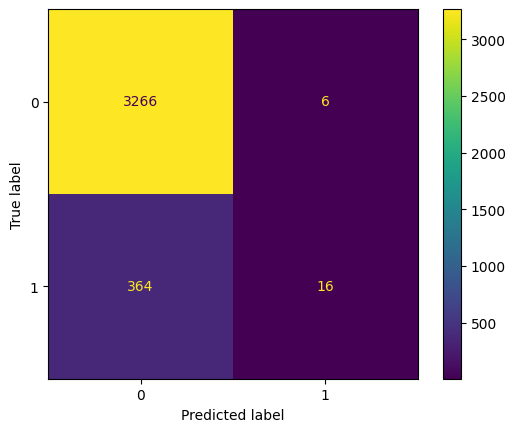

In [27]:
cm=confusion_matrix(y_test,predict)
display=ConfusionMatrixDisplay(confusion_matrix=cm)
display.plot()
plt.show()

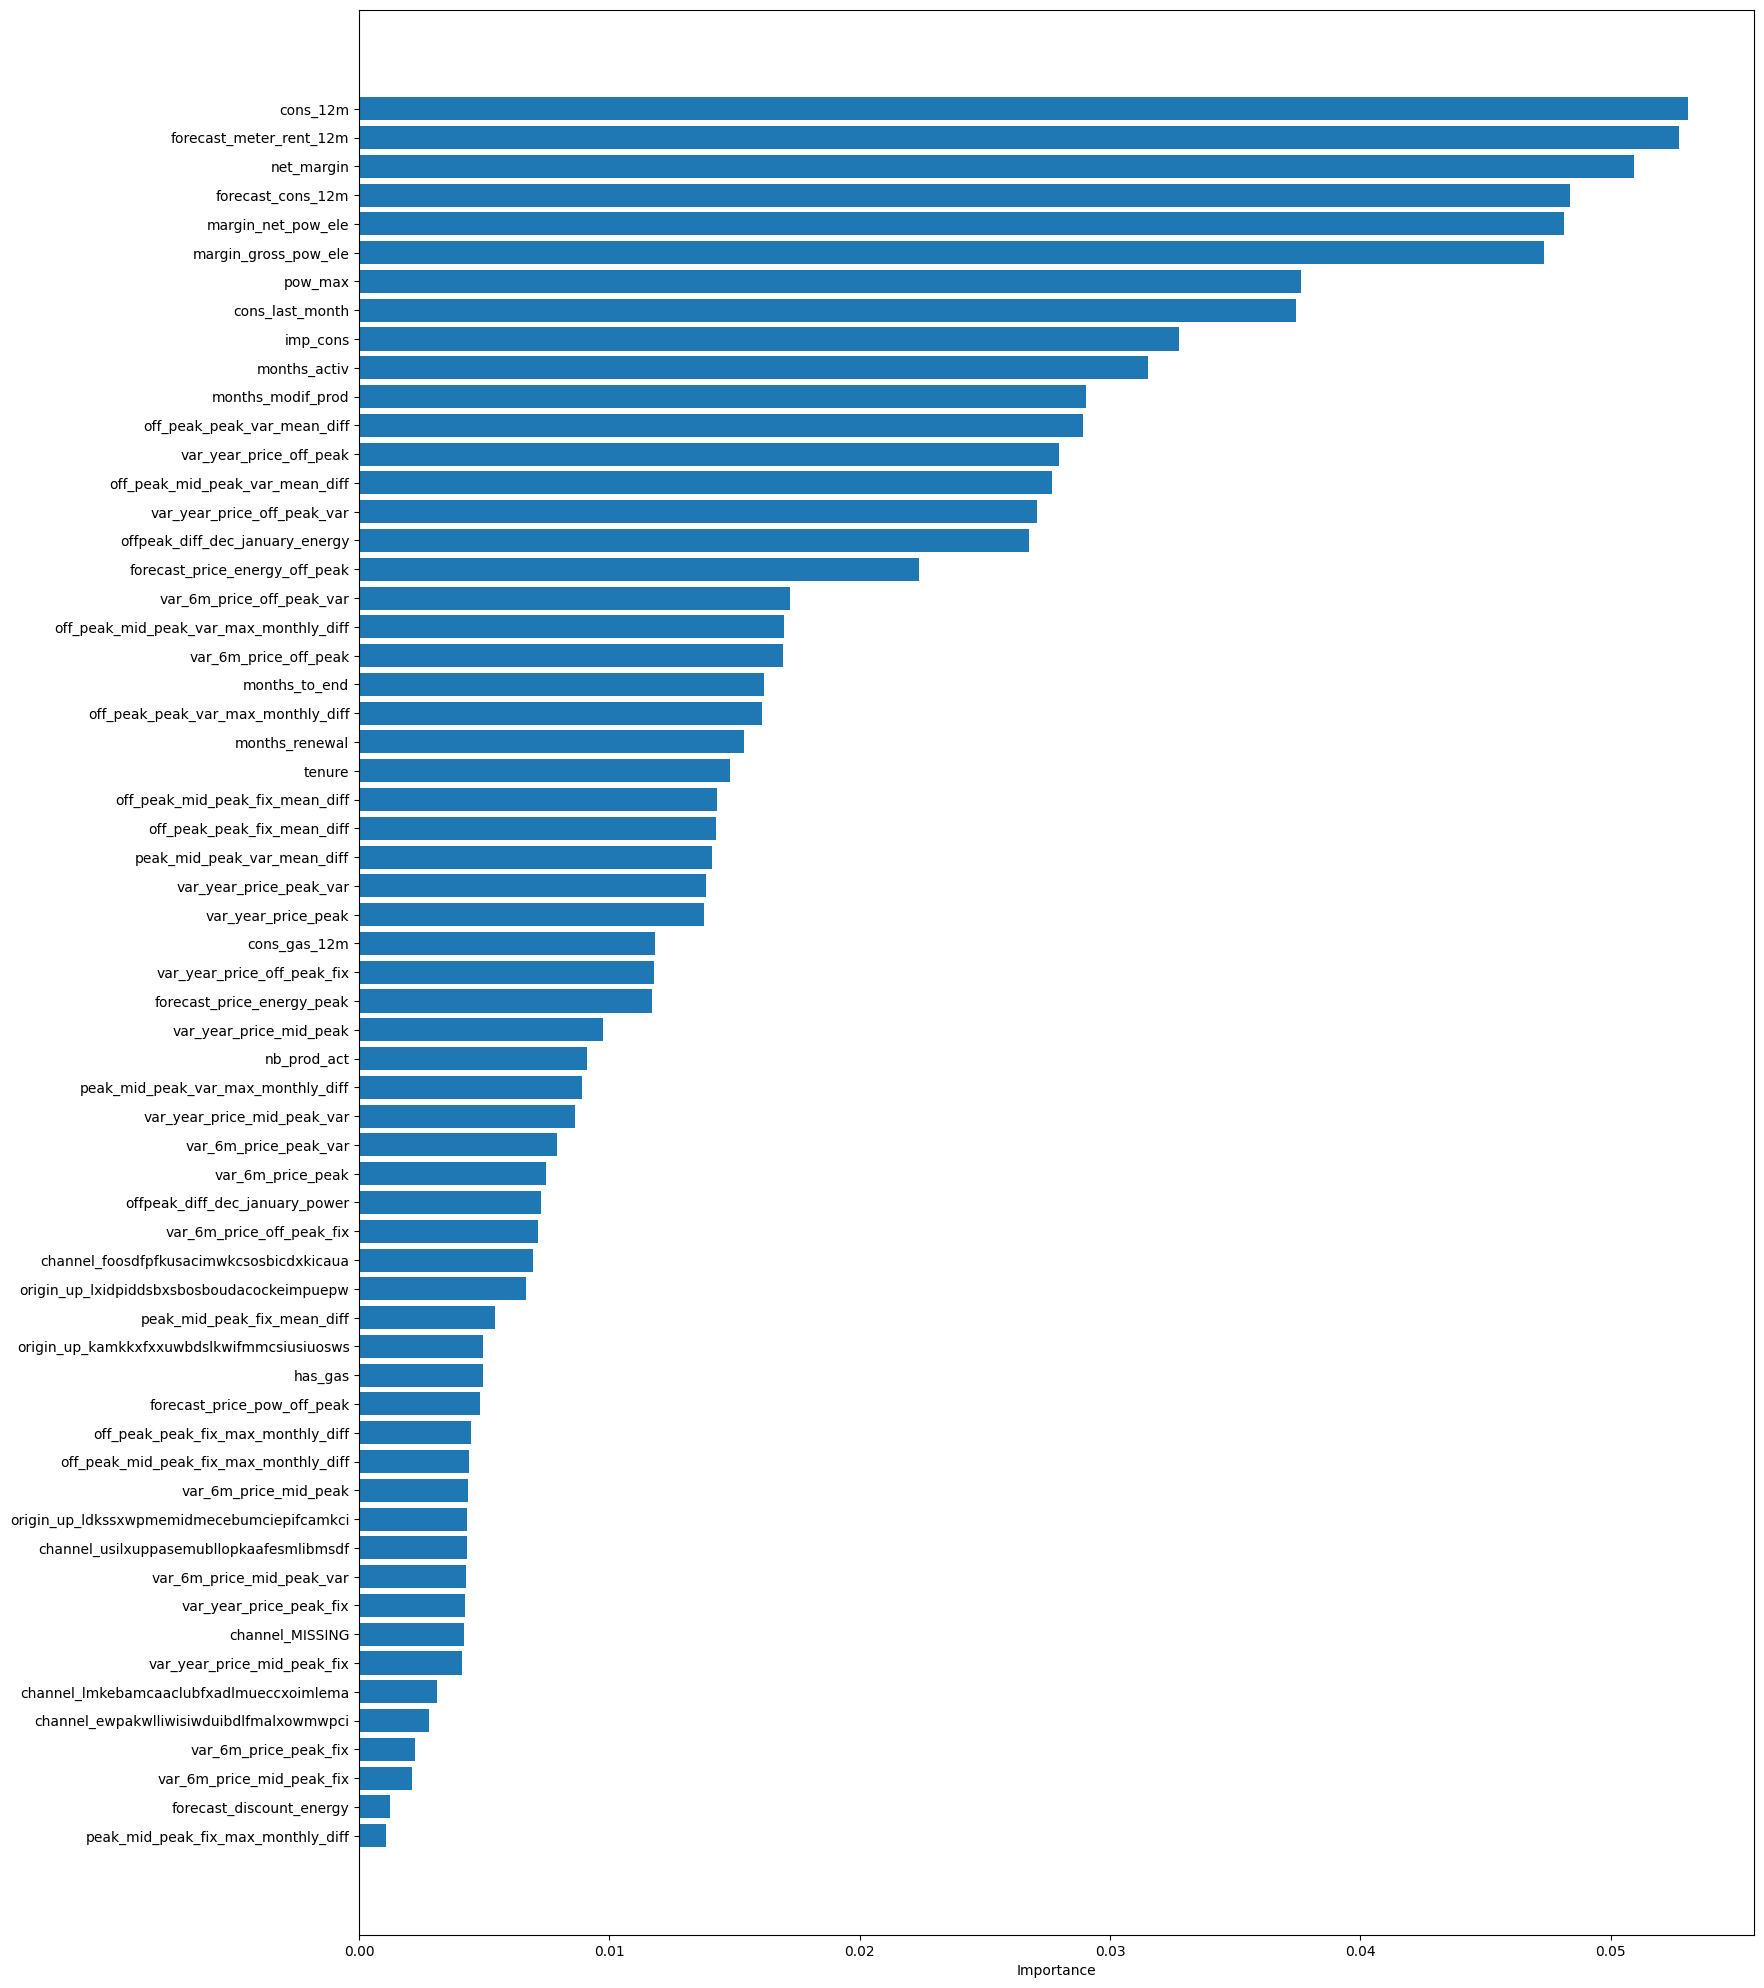

In [28]:
plt.figure(figsize=(18,25))
feature_importance=pd.DataFrame({
    "feature":x_train.columns,
    "feature_importance":model.feature_importances_
}).sort_values(by="feature_importance")

# print(feature_importance)
plt.barh(range(len(feature_importance)),feature_importance["feature_importance"])
plt.yticks(range(len(feature_importance)),feature_importance["feature"])
plt.xlabel('Importance')
plt.show()